# 06 · Explaining the late-delivery model

**Question:** Which purchase-time features push an order's late-delivery risk up
or down in the LightGBM model?

The model is the one saved by `src/train.py` (trained before Mar 2018, early
stopping on Mar-Apr 2018), the same file the API serves. It is explained on the test set (May-Aug 2018), the
orders it never saw.

**How to read SHAP values.** Every order starts at the model's average score.
Each feature then gives a push: positive = toward *late*, negative = toward
*on time*. The pushes add up to the order's final score. Scores are in
log-odds (the model's internal scale), so compare the sizes of the pushes
with each other rather than reading them as percentages.

In [1]:
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap

# Notebooks run from notebooks/, so add src/ to the import path.
sys.path.insert(0, str(Path.cwd().parent / "src"))
from features import TARGET, load_features
from train import FEATURES, MODEL_PATH, time_split

FIGURES = Path.cwd().parent / "reports" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

df = load_features()
train, valid, test = time_split(df)
# The same saved model the API serves (run src/train.py first).
model = joblib.load(MODEL_PATH)
print(f"LightGBM model with {model.best_iteration_} trees")

X_test = test[FEATURES]
risk = model.predict_proba(X_test)[:, 1]
shap_values = shap.TreeExplainer(model)(X_test)
print(f"SHAP values: {shap_values.values.shape[0]:,} orders x {shap_values.values.shape[1]} features")

/Users/saimonica/projects/Olist-Brazilian-E-commerce-project/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


LightGBM model with 111 trees


SHAP values: 25,352 orders x 21 features


## 1. Overall importance

**Question:** Which features does the model lean on most?

Bar length = the average size of a feature's push across all test orders,
ignoring direction.

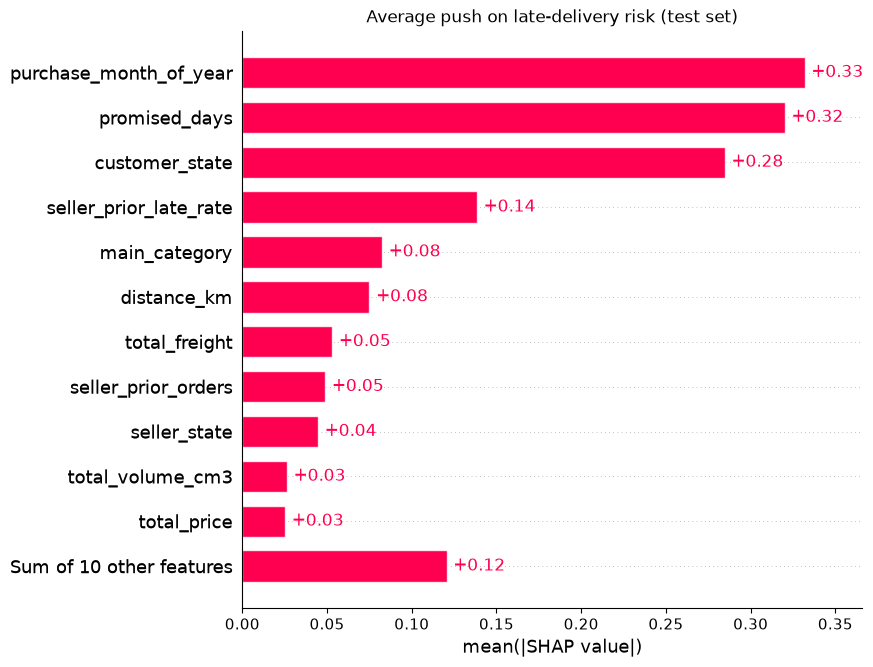

In [2]:
shap.plots.bar(shap_values, max_display=12, show=False)
plt.title("Average push on late-delivery risk (test set)")
plt.savefig(FIGURES / "06_shap_importance.png", dpi=150, bbox_inches="tight")
plt.show()

**Observations:**

- Three features dominate: purchase_month_of_year (0.33), promised_days (0.32) and customer_state (0.29). The next one, seller_prior_late_rate (0.14), is less than half as large.
- Basket-size and checkout details (n_products, max_installments, purchase_hour, purchase_dow) barely move the risk (≤ 0.01 each).
- Month of year is the top feature, but the training data covers only Jan 2017 – Feb 2018, so each month appears once or twice. The model may be memorising which months were bad in 2017 rather than learning a lasting pattern. To be tested by retraining without it.

## 2. Direction of each push

**Question:** For each numeric feature, do high values push toward late or
toward on time?

One dot per order. Horizontal position = the push. Colour = the feature's
value (red high, blue low). Grey rows are categorical features, which have no
"high" or "low"; section 3 covers them.

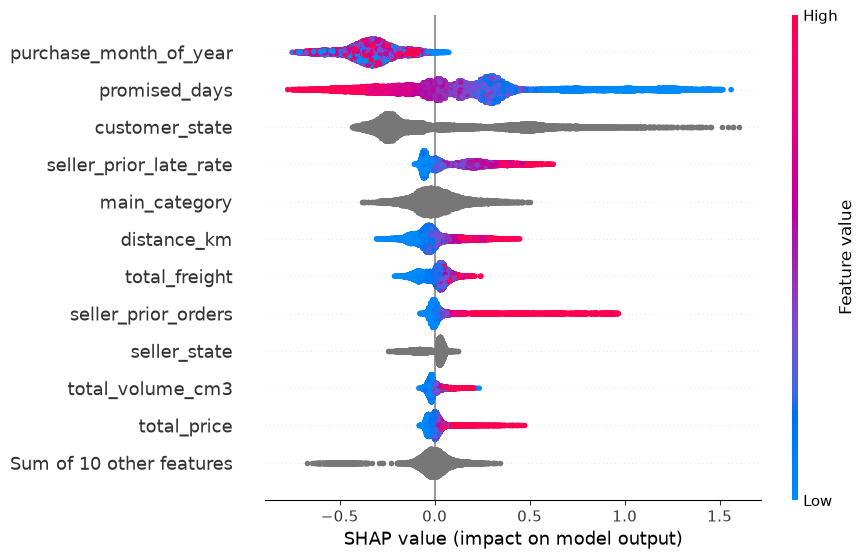

In [3]:
shap.plots.beeswarm(shap_values, max_display=12, show=False)
plt.savefig(FIGURES / "06_shap_beeswarm.png", dpi=150, bbox_inches="tight")
plt.show()

**Observations:**

- promised_days has the widest spread (about −0.8 to +1.5). Short promises (blue) push toward late; long promises (red) push toward on time. A tight promise is the strongest risk signal.
- seller_prior_late_rate, distance_km, total_freight and total_price follow one pattern: high values (red) push toward late. Sellers who were often late before, far deliveries and heavier/costlier shipments raise risk.
- seller_prior_orders: sellers with many past orders (red) push toward late, up to about +0.95. This is surprising, since experienced sellers might be expected to be more reliable. Worth checking.
- purchase_month_of_year: almost every test order is pushed toward on time (dots mostly between −0.75 and 0). The test months (May–Aug) likely looked "safe" in 2017, which matches the low 4.4% test late rate, but it supports the concern from section 1.

## 3. Customer state

**Question:** Which delivery states does the model push toward late, and which
toward on time?

Average push per state, with the state's order count and actual late rate in
the test set for comparison.

In [4]:
state_push = (
    pd.DataFrame({
        "customer_state": test["customer_state"].astype(str).values,
        "push": shap_values[:, "customer_state"].values,
        "is_late": test[TARGET].values,
    })
    .groupby("customer_state")
    .agg(orders=("push", "size"), avg_push=("push", "mean"), late_rate=("is_late", "mean"))
    .sort_values("avg_push", ascending=False)
    .round(3)
)
state_push

,orders,avg_push,late_rate
customer_state,,,
AL,81,1.203,0.074
PB,136,0.930,0.044
MA,141,0.883,0.113
SE,82,0.845,0.049
PE,412,0.699,0.063
BA,839,0.645,0.088
RN,106,0.547,0.009
CE,283,0.471,0.032
PA,194,0.457,0.041


**Observations:**

- Most risky per the model: AL (+1.20), PB (+0.93) and MA (+0.88), all in the Northeast. Safest: MG (−0.32), PR (−0.29) and SP (−0.20), in the Southeast and South, where most sellers are.
- The push doesn't always match reality. RN gets +0.55 but only 0.9% were late; PI gets a similar +0.45 but 15.3% were late. The model likely learned each state's pattern from 2017, and some states changed by 2018.
- Small states can't be trusted: RR (11 orders), AC (12), AP (16) and AM (38) all show 0% late. With so few orders, one late delivery would change the rate a lot (1 ÷ 11 ≈ 9%).
- SP has 11,749 of the 25,352 test orders (46%), so its push matters most for overall performance.

## 4. One order, explained

**Question:** Why did the model give its riskiest test order a high score?

The waterfall starts at the average score `E[f(X)]` (bottom) and adds one push
per feature until it reaches this order's score `f(x)` (top).

Order 7e225c7be8d238e6c940f116d7583a13: predicted risk 44.0%, actually late: False


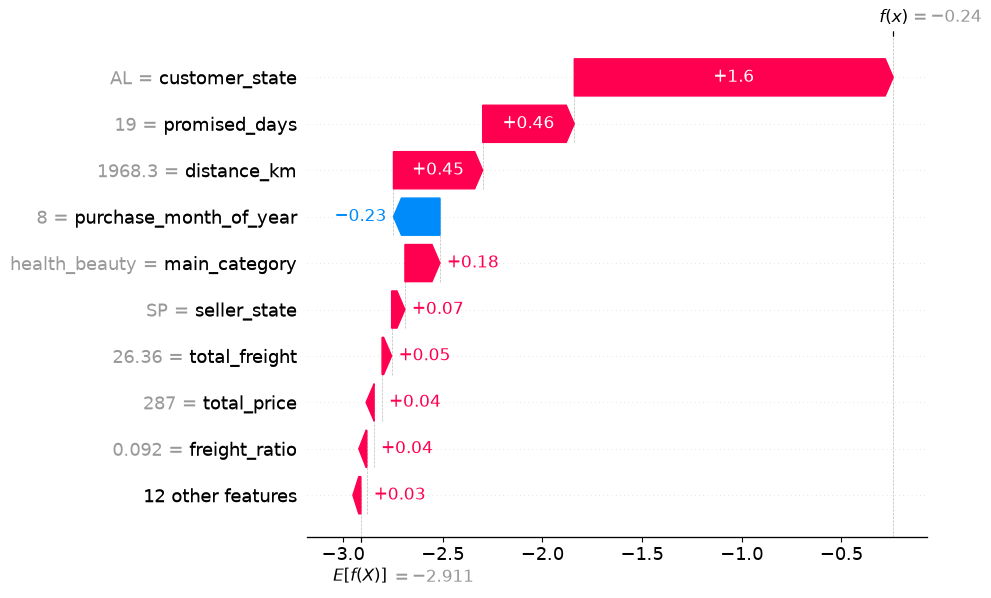

In [5]:
top = int(np.argmax(risk))
print(f"Order {test['order_id'].iloc[top]}: predicted risk {risk[top]:.1%}, "
      f"actually late: {bool(test[TARGET].iloc[top])}")

shap.plots.waterfall(shap_values[top], max_display=10, show=False)
plt.savefig(FIGURES / "06_shap_top_order.png", dpi=150, bbox_inches="tight")
plt.show()

**Observations:**

- The riskiest test order scored 44.0%, compared with a starting point of about 5% for an average order. It was not actually late.
- The biggest push by far is customer_state = AL (+1.6), more than three times the next ones: promised_days = 19 (+0.46) and distance_km = 1,968 (+0.45). Delivering far away to a state the model sees as risky explains most of the score.
- Only purchase_month_of_year = 8 (August) pulled toward on time (−0.23).
- Even the riskiest order is below 50%, so a risk score means "check this one," not "this will be late." An on-time result here isn't a model failure. Ops would expect many flagged orders to arrive fine (in section 4 of train.py's output, only ~11% of the top 10% were late).